# Group 3 MVTec AD — Complete Project Notebook

This consolidated Google Colab notebook contains the complete project workflow in chronological order:

1. **Day 1 — Data Understanding**
2. **Weeks 3–4 — Data Cleaning and Exploratory Data Analysis (EDA)**
3. **Assignment 4 — Machine Learning Model Development**
4. **Weeks 6–7 — Streamlit Application Handoff**

The original code, explanations and visible outputs from the three project notebooks have been retained. The selected Assignment 4 model is a **Random Forest** trained using image-derived colour/texture statistics, image dimensions and one-hot encoded product category.

> The Week 6–7 Streamlit application is submitted as a separate `app.py` project because Streamlit is a web application, not a Colab execution requirement. A documentation section at the end records how the notebook model is connected to the application.


## Contents

- **Section 1:** Day 1 — Data Understanding
- **Section 2:** Weeks 3–4 — Data Cleaning and EDA
- **Section 3:** Assignment 4 — Model Development and Evaluation
- **Section 4:** Weeks 6–7 — Streamlit Application Handoff


# Day 1 — Data Understanding

Source notebook: `Group3_Week2_Day1.ipynb`

In [ ]:
from google.colab import drive

drive.mount('/content/drive')

from pathlib import Path

root = Path('/content/drive/MyDrive/mvtec_anomaly_detection')
print(root.exists())
print(list(root.iterdir())[:5])


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
True
[PosixPath('/content/drive/MyDrive/mvtec_anomaly_detection/license.txt'), PosixPath('/content/drive/MyDrive/mvtec_anomaly_detection/readme.txt'), PosixPath('/content/drive/MyDrive/mvtec_anomaly_detection/wood'), PosixPath('/content/drive/MyDrive/mvtec_anomaly_detection/bottle'), PosixPath('/content/drive/MyDrive/mvtec_anomaly_detection/screw')]


This cell first mounts Google Drive to `/content/drive`, allowing access to files stored in your Drive. It then defines a `Path` object `root` pointing to the `mvtec_anomaly_detection` directory within your Google Drive. Finally, it checks if this root directory exists and prints the first 5 items within it.

This cell imports the `pandas` library, which is essential for data manipulation and analysis in Python, and prints a confirmation message.

This code block first prints the shape of the DataFrame `df`, which represents the number of rows and columns. Then, it explicitly prints the number of rows and columns using `df.shape[0]` and `df.shape[1]` respectively.

In [ ]:
from pathlib import Path
import pandas as pd
from PIL import Image

root = Path('/content/drive/MyDrive/mvtec_anomaly_detection')

records = []

for category_dir in sorted(root.iterdir()):
    if not category_dir.is_dir() or category_dir.name == 'ground_truth':
        continue

    category = category_dir.name

    for split in ['train', 'test']:
        split_dir = category_dir / split

        if not split_dir.exists():
            continue

        for defect_dir in sorted(split_dir.iterdir()):
            if not defect_dir.is_dir():
                continue

            defect_type = defect_dir.name
            image_label = 0 if defect_type == 'good' else 1

            for image_path in sorted(defect_dir.glob('*.png')):
                with Image.open(image_path) as image:
                    width, height = image.size

                mask_path = None

                if image_label == 1:
                    possible_mask = (
                        category_dir
                        / 'ground_truth'
                        / defect_type
                        / f'{image_path.stem}_mask.png'
                    )

                    if possible_mask.exists():
                        mask_path = str(possible_mask)

                records.append({
                    'image_path': str(image_path),
                    'category': category,
                    'split': split,
                    'defect_type': defect_type,
                    'image_label': image_label,
                    'mask_path': mask_path,
                    'width': width,
                    'height': height
                })

df = pd.DataFrame(records)

print(df.shape)

(3260, 8)


This code iterates through the specified root directory, which contains image data organized by category and split (train/test). It extracts metadata for each image, such as its path, category, split, defect type, and whether it's a defective image (image_label). If an image is defective, it also attempts to find a corresponding mask path. All this information is then compiled into a pandas DataFrame called `df`. Finally, it prints the shape of the DataFrame.

In [ ]:
df.head()

,image_path,category,split,defect_type,image_label,mask_path,width,height
0,/content/drive/MyDrive/mvtec_anomaly_detection...,bottle,train,good,0,None,900,900
1,/content/drive/MyDrive/mvtec_anomaly_detection...,bottle,train,good,0,None,900,900
2,/content/drive/MyDrive/mvtec_anomaly_detection...,bottle,train,good,0,None,900,900
3,/content/drive/MyDrive/mvtec_anomaly_detection...,bottle,train,good,0,None,900,900
4,/content/drive/MyDrive/mvtec_anomaly_detection...,bottle,train,good,0,None,900,900


This cell displays the first 5 rows of the `df` DataFrame. This is useful for a quick visual inspection of the data structure and content.

In [ ]:
df.tail()

,image_path,category,split,defect_type,image_label,mask_path,width,height
3255,/content/drive/MyDrive/mvtec_anomaly_detection...,zipper,test,squeezed_teeth,1,/content/drive/MyDrive/mvtec_anomaly_detection...,1024,1024
3256,/content/drive/MyDrive/mvtec_anomaly_detection...,zipper,test,squeezed_teeth,1,/content/drive/MyDrive/mvtec_anomaly_detection...,1024,1024
3257,/content/drive/MyDrive/mvtec_anomaly_detection...,zipper,test,squeezed_teeth,1,/content/drive/MyDrive/mvtec_anomaly_detection...,1024,1024
3258,/content/drive/MyDrive/mvtec_anomaly_detection...,zipper,test,squeezed_teeth,1,/content/drive/MyDrive/mvtec_anomaly_detection...,1024,1024
3259,/content/drive/MyDrive/mvtec_anomaly_detection...,zipper,test,squeezed_teeth,1,/content/drive/MyDrive/mvtec_anomaly_detection...,1024,1024


This cell displays the last 5 rows of the `df` DataFrame, which can be helpful to see the end of the dataset and ensure all data was loaded correctly.

In [ ]:
df.sample(5)

,image_path,category,split,defect_type,image_label,mask_path,width,height
475,/content/drive/MyDrive/mvtec_anomaly_detection...,carpet,train,good,0,None,1024,1024
537,/content/drive/MyDrive/mvtec_anomaly_detection...,carpet,train,good,0,None,1024,1024
471,/content/drive/MyDrive/mvtec_anomaly_detection...,carpet,train,good,0,None,1024,1024
1173,/content/drive/MyDrive/mvtec_anomaly_detection...,leather,test,good,0,None,1024,1024
431,/content/drive/MyDrive/mvtec_anomaly_detection...,carpet,train,good,0,None,1024,1024


This cell displays 5 random rows from the `df` DataFrame. Sampling provides a good overview of the data's diversity without having to look at the entire dataset.

In [ ]:
df.columns
print(df.columns.tolist())

['image_path', 'category', 'split', 'defect_type', 'image_label', 'mask_path', 'width', 'height']


This cell first accesses the column names of the `df` DataFrame using `df.columns`. Then, it converts the column names to a Python list and prints them, providing a clear list of all variables in the dataset.

In [ ]:
df.columns.tolist()

['image_path',
 'category',
 'split',
 'defect_type',
 'image_label',
 'mask_path',
 'width',
 'height']

This cell directly returns the column names of the `df` DataFrame as a list, which is useful for programmatic access to column names.

This cell provides a concise summary of the `df` DataFrame, including the number of entries, the number of non-null values for each column, the data type of each column, and memory usage. This helps in understanding data completeness and types.

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3260 entries, 0 to 3259
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   image_path   3260 non-null   object
 1   category     3260 non-null   object
 2   split        3260 non-null   object
 3   defect_type  3260 non-null   object
 4   image_label  3260 non-null   int64 
 5   mask_path    783 non-null    object
 6   width        3260 non-null   int64 
 7   height       3260 non-null   int64 
dtypes: int64(3), object(5)
memory usage: 203.9+ KB


In [ ]:
df.dtypes

,0
image_path,object
category,object
split,object
defect_type,object
image_label,int64
mask_path,object
width,int64
height,int64


This cell displays the data type of each column in the `df` DataFrame, which is crucial for data preprocessing and ensuring data integrity.

In [ ]:
print("Categories:")
print(df.select_dtypes(include="object").columns.tolist())

Categories:
['image_path', 'category', 'split', 'defect_type', 'mask_path']


This cell identifies and prints the names of columns in the `df` DataFrame that have an 'object' data type. These usually correspond to categorical or string-based features.

In [ ]:
df.describe()

,image_label,width,height
count,3260.000000,3260.000000,3260.000000
mean,0.240184,931.434356,931.434356
std,0.427261,116.856858,116.856858
min,0.000000,700.000000,700.000000
25%,0.000000,840.000000,840.000000
50%,0.000000,1024.000000,1024.000000
75%,0.000000,1024.000000,1024.000000
max,1.000000,1024.000000,1024.000000


This cell generates descriptive statistics for the numerical columns in the `df` DataFrame, including count, mean, standard deviation, min, max, and quartiles. This helps in understanding the distribution and central tendency of numerical data.

In [ ]:
df[['image_label', 'width', 'height']].describe()

,image_label,width,height
count,3260.000000,3260.000000,3260.000000
mean,0.240184,931.434356,931.434356
std,0.427261,116.856858,116.856858
min,0.000000,700.000000,700.000000
25%,0.000000,840.000000,840.000000
50%,0.000000,1024.000000,1024.000000
75%,0.000000,1024.000000,1024.000000
max,1.000000,1024.000000,1024.000000


This cell generates descriptive statistics (count, mean, standard deviation, min, max, and quartiles) specifically for the 'image_label', 'width', and 'height' columns. This helps in understanding the distribution and central tendency of these key numerical features.

This cell calculates and displays the frequency of each unique value in the 'category' column. This helps in understanding the distribution of different anomaly categories within the dataset.

In [ ]:
df['category'].value_counts()

,count
category,
screw,480
pill,434
carpet,396
zipper,391
grid,342
metal_nut,335
tile,325
bottle,292
leather,163


This cell calculates the percentage of each unique value in the 'category' column, rounded to two decimal places. This provides a normalized view of the category distribution.

In [ ]:
df['category'].value_counts(normalize=True).mul(100).round(2)

,proportion
category,
screw,14.72
pill,13.31
carpet,12.15
zipper,11.99
grid,10.49
metal_nut,10.28
tile,9.97
bottle,8.96
leather,5.00


This cell calculates and displays the frequency of each unique value in the 'split' column (e.g., 'train', 'test'). This is important for understanding the dataset's division into training and testing sets.

In [ ]:
df['split'].value_counts()

,count
split,
train,2210
test,1050


This cell calculates the percentage of each unique value in the 'split' column, rounded to two decimal places. This provides a normalized view of how the data is split.

In [ ]:
df['split'].value_counts(normalize=True).mul(100).round(2)

,proportion
split,
train,67.79
test,32.21


This cell calculates and displays the frequency of each unique value in the 'image_label' column (0 for good, 1 for anomaly). This gives insight into the balance of anomaly versus non-anomaly images.

In [ ]:
df['image_label'].value_counts()

,count
image_label,
0,2477
1,783


This cell calculates the percentage of each unique value in the 'image_label' column, rounded to two decimal places. This provides a normalized view of the proportion of good versus anomalous images.

In [ ]:
df['image_label'].value_counts(normalize=True).mul(100).round(2)

,proportion
image_label,
0,75.98
1,24.02


In [ ]:
df.isnull().sum()

,0
image_path,0
category,0
split,0
defect_type,0
image_label,0
mask_path,2477
width,0
height,0


This cell calculates and displays the number of missing (null) values for each column in the `df` DataFrame. This helps in identifying columns with incomplete data that might require cleaning or imputation.

In [ ]:
df.duplicated().sum()

np.int64(0)

This cell calculates and displays the total number of duplicate rows in the `df` DataFrame. Identifying duplicate rows is important for data quality, as duplicates can skew analysis and model training.

# Weeks 3–4 — Data Cleaning and Exploratory Data Analysis

Source notebook: `Group3_week3.ipynb`

In [ ]:
from google.colab import drive

drive.mount('/content/drive')

from pathlib import Path

root = Path('/content/drive/MyDrive/mvtec_anomaly_detection')
print(root.exists())
print(list(root.iterdir())[:5])

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
True
[PosixPath('/content/drive/MyDrive/mvtec_anomaly_detection/license.txt'), PosixPath('/content/drive/MyDrive/mvtec_anomaly_detection/readme.txt'), PosixPath('/content/drive/MyDrive/mvtec_anomaly_detection/wood'), PosixPath('/content/drive/MyDrive/mvtec_anomaly_detection/bottle'), PosixPath('/content/drive/MyDrive/mvtec_anomaly_detection/screw')]


This cell mounts Google Drive to the Colab environment, making files stored in your Drive accessible. It then defines a `pathlib.Path` object to the base directory of the MVTec Anomaly Detection dataset and prints whether the path exists and lists the first few items within that directory. The output confirms that the drive is mounted, the path exists (`True`), and shows the initial files and directories.

In [ ]:
from pathlib import Path
import pandas as pd
from PIL import Image

root = Path('/content/drive/MyDrive/mvtec_anomaly_detection')

records = []

for category_dir in sorted(root.iterdir()):
    if not category_dir.is_dir() or category_dir.name == 'ground_truth':
        continue

    category = category_dir.name

    for split in ['train', 'test']:
        split_dir = category_dir / split

        if not split_dir.exists():
            continue

        for defect_dir in sorted(split_dir.iterdir()):
            if not defect_dir.is_dir():
                continue

            defect_type = defect_dir.name
            image_label = 0 if defect_type == 'good' else 1

            for image_path in sorted(defect_dir.glob('*.png')):
                with Image.open(image_path) as image:
                    width, height = image.size

                mask_path = None

                if image_label == 1:
                    possible_mask = (
                        category_dir
                        / 'ground_truth'
                        / defect_type
                        / f'{image_path.stem}_mask.png'
                    )

                    if possible_mask.exists():
                        mask_path = str(possible_mask)

                records.append({
                    'image_path': str(image_path),
                    'category': category,
                    'split': split,
                    'defect_type': defect_type,
                    'image_label': image_label,
                    'mask_path': mask_path,
                    'width': width,
                    'height': height
                })

df = pd.DataFrame(records)

print(df.shape)

(3260, 8)


This cell iterates through the dataset structure stored in Google Drive. It processes each category and split (`train`, `test`) to extract information about the images, such as their path, category, split, defect type, image label (0 for good, 1 for defective), mask path (if applicable), and image dimensions (width, height). This extracted information is then compiled into a pandas DataFrame. The output `(3260, 8)` indicates that the DataFrame has 3260 rows (images) and 8 columns (features).

In [ ]:
df_raw = df.copy()
df = df_raw.copy()
print('Raw shape:', df_raw.shape)

Raw shape: (3260, 8)


This cell creates a raw copy of the initial DataFrame (`df_raw = df.copy()`) and then makes another working copy (`df = df_raw.copy()`). This is a common practice to preserve the original imported data for later reference or reprocessing. The output `Raw shape: (3260, 8)` confirms the dimensions of the copied DataFrame.

In [ ]:
print(df.shape)
df.info()
print(df.dtypes)
print(df.isnull().sum())
print(df.isnull().mean().mul(100).round(2))
print('Duplicates:', df.duplicated().sum())
print(df.nunique())
for c in ['category', 'split', 'defect_type', 'image_label']:
    print(c)
    print(df[c].value_counts(dropna=False))

(3260, 8)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3260 entries, 0 to 3259
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   image_path   3260 non-null   object
 1   category     3260 non-null   object
 2   split        3260 non-null   object
 3   defect_type  3260 non-null   object
 4   image_label  3260 non-null   int64 
 5   mask_path    783 non-null    object
 6   width        3260 non-null   int64 
 7   height       3260 non-null   int64 
dtypes: int64(3), object(5)
memory usage: 203.9+ KB
image_path     object
category       object
split          object
defect_type    object
image_label     int64
mask_path      object
width           int64
height          int64
dtype: object
image_path        0
category          0
split             0
defect_type       0
image_label       0
mask_path      2477
width             0
height            0
dtype: int64
image_path      0.00
category        0.00
split           0

This cell performs initial exploratory data analysis to understand the dataset's structure and contents. It prints:  
- **`df.shape`**: The number of rows and columns.  
- **`df.info()`**: A summary of the DataFrame, including data types, non-null counts, and memory usage.  
- **`df.dtypes`**: The data type of each column.  
- **`df.isnull().sum()`**: The count of missing values per column.  
- **`df.isnull().mean().mul(100).round(2)`**: The percentage of missing values per column.  
- **`df.duplicated().sum()`**: The number of duplicate rows.  
- **`df.nunique()`**: The number of unique values in each column.  
- **`df[c].value_counts(dropna=False)`**: The frequency distribution of key categorical columns (`category`, `split`, `defect_type`, `image_label`). The output shows that `mask_path` has 2477 missing values (75.98%), indicating that most images are 'good' and thus don't have an associated mask.

In [ ]:
df['mask_path'] = df['mask_path'].fillna('NOT_APPLICABLE').astype('string')
for c in ['image_path', 'category', 'split', 'defect_type']:
    df[c] = df[c].astype('string').str.strip()
for c in ['image_label', 'width', 'height']:
    df[c] = pd.to_numeric(df[c], errors='coerce')
df = df.drop_duplicates().copy()
display(df.head())

,image_path,category,split,defect_type,image_label,mask_path,width,height
0,/content/drive/MyDrive/mvtec_anomaly_detection...,bottle,train,good,0,NOT_APPLICABLE,900,900
1,/content/drive/MyDrive/mvtec_anomaly_detection...,bottle,train,good,0,NOT_APPLICABLE,900,900
2,/content/drive/MyDrive/mvtec_anomaly_detection...,bottle,train,good,0,NOT_APPLICABLE,900,900
3,/content/drive/MyDrive/mvtec_anomaly_detection...,bottle,train,good,0,NOT_APPLICABLE,900,900
4,/content/drive/MyDrive/mvtec_anomaly_detection...,bottle,train,good,0,NOT_APPLICABLE,900,900


This cell cleans and prepares the data for further analysis.  - It fills the `mask_path` column's missing values with the string 'NOT_APPLICABLE' and converts the column to a string type.  
- It converts several other categorical columns (`image_path`, `category`, `split`, `defect_type`) to string type and removes any leading/trailing whitespace.  
- It converts numerical columns (`image_label`, `width`, `height`) to numeric types, coercing any errors to `NaN` (though none are expected here based on previous info).  - Finally, it drops any duplicate rows that might exist, ensuring unique entries, and then displays the first 5 rows of the cleaned DataFrame. This allows for a quick check of the data after the cleaning steps.

In [ ]:
clean_path = '/content/drive/MyDrive/cleaned_project_dataset.csv'
df.to_csv(clean_path, index=False)
print('Saved:', clean_path)

Saved: /content/drive/MyDrive/cleaned_project_dataset.csv


This cell saves the cleaned DataFrame (`df`) to a CSV file named `cleaned_project_dataset.csv` in your Google Drive. The `index=False` argument prevents pandas from writing the DataFrame index as a column in the CSV. The output confirms the file has been successfully saved to the specified path.

In [ ]:
df = pd.read_csv('/content/drive/MyDrive/cleaned_project_dataset.csv')
print(df.shape)
df.info()
print(df[['image_label','width','height']].describe().T)
print(df['image_label'].value_counts())
print(df['image_label'].value_counts(normalize=True).mul(100).round(2))
print(df['category'].value_counts())
print(df['split'].value_counts())

(3260, 8)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3260 entries, 0 to 3259
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   image_path   3260 non-null   object
 1   category     3260 non-null   object
 2   split        3260 non-null   object
 3   defect_type  3260 non-null   object
 4   image_label  3260 non-null   int64 
 5   mask_path    3260 non-null   object
 6   width        3260 non-null   int64 
 7   height       3260 non-null   int64 
dtypes: int64(3), object(5)
memory usage: 203.9+ KB
              count        mean         std    min    25%     50%     75%  \
image_label  3260.0    0.240184    0.427261    0.0    0.0     0.0     0.0   
width        3260.0  931.434356  116.856858  700.0  840.0  1024.0  1024.0   
height       3260.0  931.434356  116.856858  700.0  840.0  1024.0  1024.0   

                max  
image_label     1.0  
width        1024.0  
height       1024.0  
image_label
0    2477
1  

This cell reloads the `cleaned_project_dataset.csv` file into a DataFrame, ensuring that subsequent analysis uses the consistent, cleaned version of the data. It then prints:  
- **`df.shape`**: The dimensions of the reloaded DataFrame.  
- **`df.info()`**: A summary of data types and non-null counts, confirming the cleaning steps.  
- **`df[['image_label','width','height']].describe().T`**: Transposed descriptive statistics for the numerical columns, showing count, mean, standard deviation, min, max, and quartiles.  
- **`df['image_label'].value_counts()` and `df['image_label'].value_counts(normalize=True).mul(100).round(2)`**: The counts and percentage distribution of the target variable (`image_label`), highlighting the class imbalance.  
- **`df['category'].value_counts()` and `df['split'].value_counts()`**: The distribution of images across different categories and dataset splits. The output consistently shows the 3260 rows and 8 columns, with `mask_path` now being an object type without missing values due to the fillna operation.

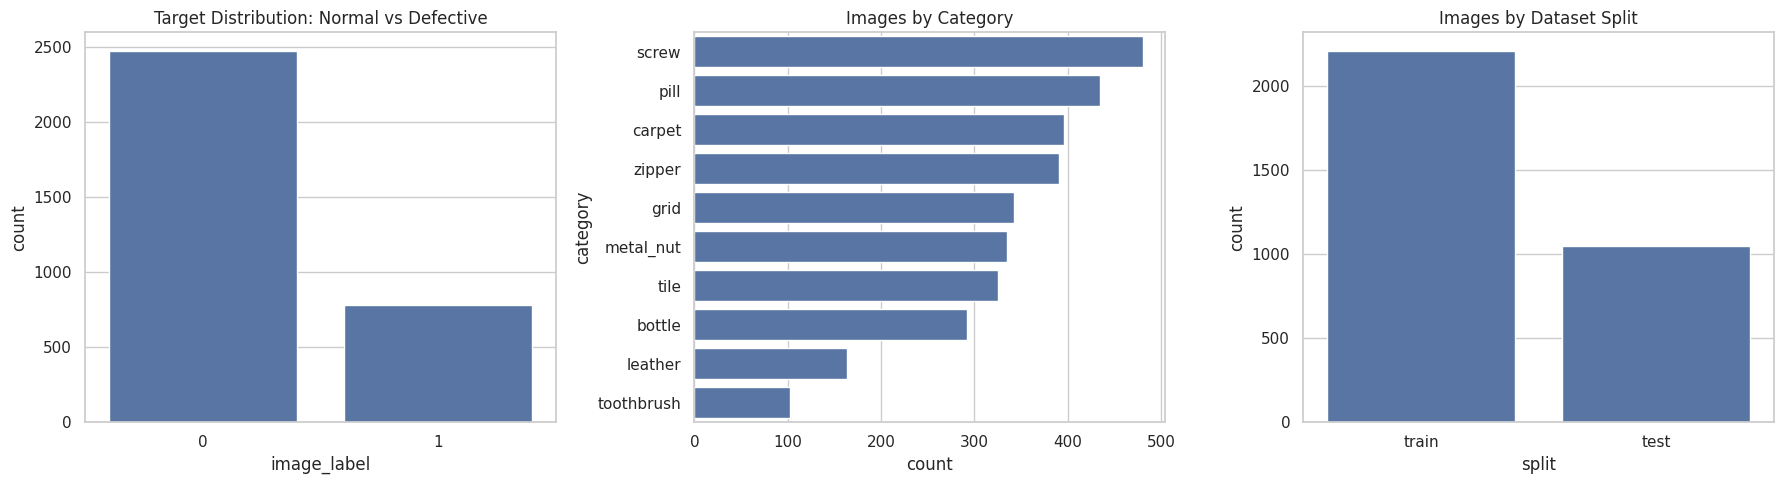

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
sns.set_theme(style='whitegrid')
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
sns.countplot(data=df, x='image_label', ax=ax[0])
ax[0].set_title('Target Distribution: Normal vs Defective')
sns.countplot(data=df, y='category', order=df['category'].value_counts().index, ax=ax[1])
ax[1].set_title('Images by Category')
sns.countplot(data=df, x='split', ax=ax[2])
ax[2].set_title('Images by Dataset Split')
plt.tight_layout()
plt.savefig('distribution_plots.png')
plt.show()

This cell generates three count plots using `seaborn` and `matplotlib` to visualize key distributions in the dataset:
 1.  **Target Distribution**: Shows the number of normal (0) vs. defective (1) images.  
 2.  **Images by Category**: Displays the count of images for each product category.  
 3.  **Images by Dataset Split**: Illustrates the distribution of images between the training and testing sets.  The `plt.tight_layout()` function adjusts plot parameters for a tight layout, `plt.savefig('distribution_plots.png')` saves the combined plot as an image file, and `plt.show()` displays the plot in the notebook.

image_label       0      1
category                  
bottle        78.42  21.58
carpet        77.53  22.47
grid          83.33  16.67
leather      100.00   0.00
metal_nut     72.24  27.76
pill          67.51  32.49
screw         75.21  24.79
tile          77.85  22.15
toothbrush    70.59  29.41
zipper        69.57  30.43
image_label       0      1
split                     
test          25.43  74.57
train        100.00   0.00


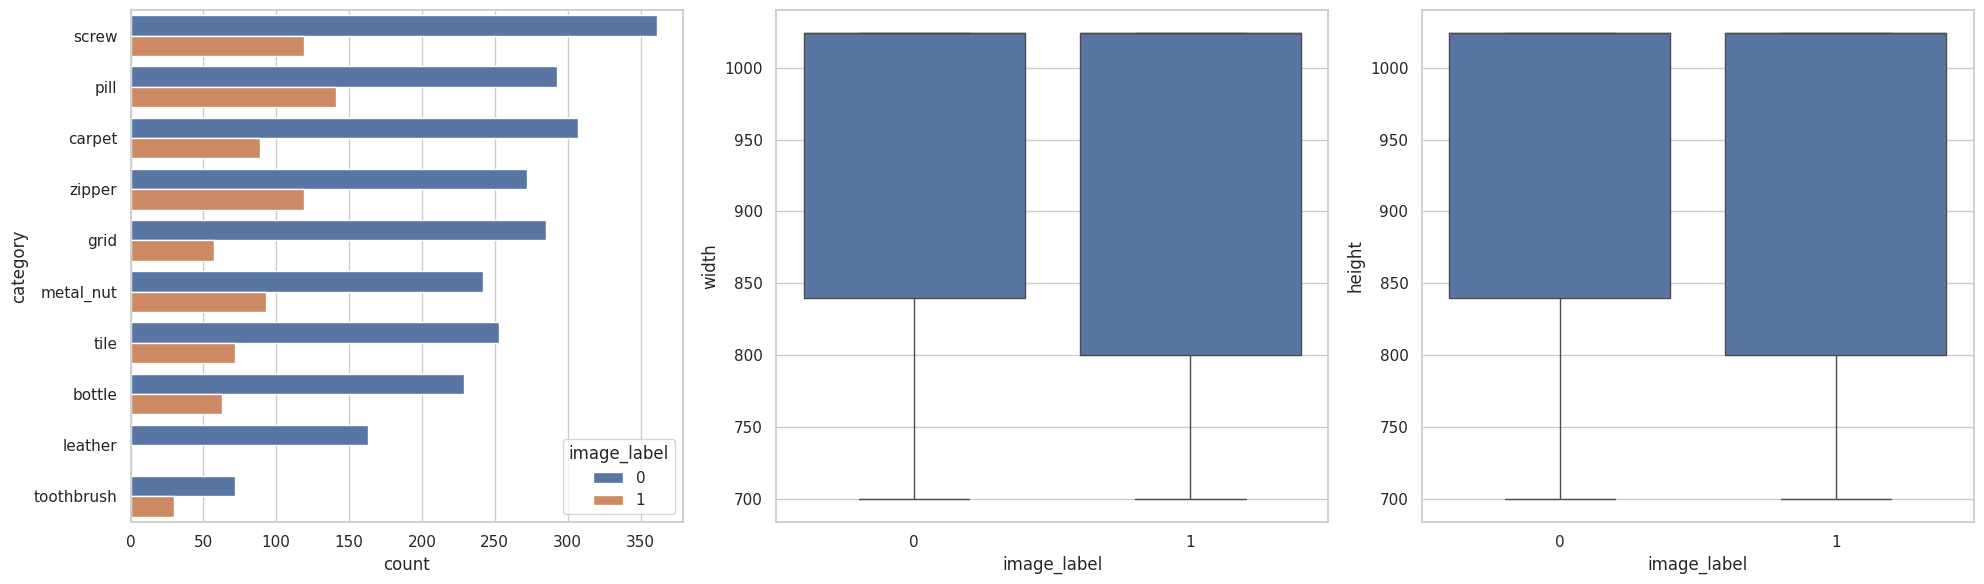

In [ ]:
mprint(pd.crosstab(df['category'], df['image_label'], normalize='index').mul(100).round(2))
print(pd.crosstab(df['split'], df['image_label'], normalize='index').mul(100).round(2))
fig, ax = plt.subplots(1, 3, figsize=(20, 6))
sns.countplot(data=df, y='category', hue='image_label', order=df['category'].value_counts().index, ax=ax[0])
sns.boxplot(data=df, x='image_label', y='width', ax=ax[1])
sns.boxplot(data=df, x='image_label', y='height', ax=ax[2])
plt.tight_layout()
plt.savefig('category_split_plots.png')
plt.show()

This cell provides more detailed insights through cross-tabulations and box plots:  
- **Cross-tabulations**:  - `pd.crosstab(df['category'], df['image_label'], normalize='index').mul(100).round(2)`: Shows the percentage of normal vs. defective images within each category.  
- `pd.crosstab(df['split'], df['image_label'], normalize='index').mul(100).round(2)`: Shows the percentage of normal vs. defective images within each dataset split (train/test).  
- **Plots**:  - A count plot of `category` vs. `image_label` to visualize defect distribution per category.  
- Box plots of `width` and `height` against `image_label` to check if image dimensions differ significantly between normal and defective images. The output shows the calculated percentage cross-tabulations before the plots are rendered.

             image_label     width    height
image_label     1.000000 -0.063282 -0.063282
width          -0.063282  1.000000  1.000000
height         -0.063282  1.000000  1.000000


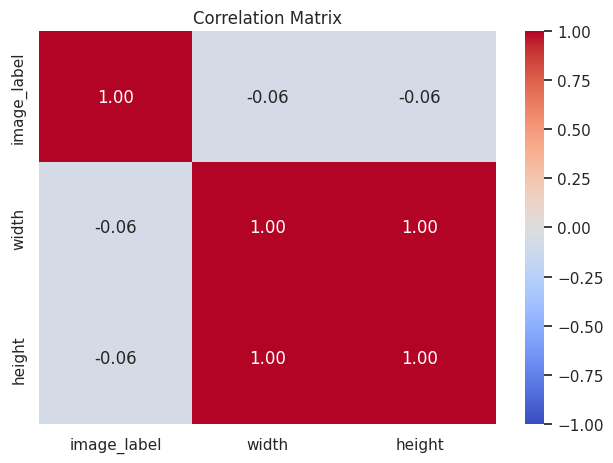

In [ ]:
numeric_df = df[['image_label', 'width', 'height']]
correlation = numeric_df.corr()
print(correlation)
sns.heatmap(correlation, annot=True, cmap='coolwarm', fmt='.2f', vmin=-1, vmax=1)
plt.title('Correlation Matrix')
plt.tight_layout()
plt.savefig('correlation_heatmap.png')
plt.show()

This cell calculates and visualizes the correlation matrix for the numerical features: `image_label`, `width`, and `height`.  - `numeric_df = df[['image_label', 'width', 'height']]`: Creates a subset DataFrame with only these columns.
- `correlation = numeric_df.corr()`: Computes the pairwise correlation between the columns.  
- `sns.heatmap(correlation, annot=True, cmap='coolwarm', fmt='.2f', vmin=-1, vmax=1)`: Generates a heatmap of the correlation matrix, showing the correlation coefficients with annotations and a 'coolwarm' color scheme.  The output first prints the correlation matrix table, then displays the heatmap visualization.

# Assignment 4 — Machine Learning Model Development

Source notebook: `Assignment4_ML_Model_Development.ipynb`

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
from PIL import Image
from tqdm.auto import tqdm

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay, classification_report
)
import joblib

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)


This cell imports all the necessary Python libraries for data manipulation, visualization, machine learning, and image processing, and sets a random state for reproducibility.

In [ ]:
CSV_PATH = "/content/drive/MyDrive/cleaned_project_dataset.csv"
if not os.path.exists(CSV_PATH):
    CSV_PATH = "/content/cleaned_project_dataset.csv"

if not os.path.exists(CSV_PATH):
    from google.colab import files
    print("CSV not found at CSV_PATH -- please upload it now:")
    uploaded = files.upload()
    CSV_PATH = list(uploaded.keys())[0]

df = pd.read_csv(CSV_PATH)
print ("The shape of the dataset is:", df.shape)
df.head()

The shape of the dataset is: (3260, 8)


,image_path,category,split,defect_type,image_label,mask_path,width,height
0,/content/drive/MyDrive/mvtec_anomaly_detection...,bottle,train,good,0,NOT_APPLICABLE,900,900
1,/content/drive/MyDrive/mvtec_anomaly_detection...,bottle,train,good,0,NOT_APPLICABLE,900,900
2,/content/drive/MyDrive/mvtec_anomaly_detection...,bottle,train,good,0,NOT_APPLICABLE,900,900
3,/content/drive/MyDrive/mvtec_anomaly_detection...,bottle,train,good,0,NOT_APPLICABLE,900,900
4,/content/drive/MyDrive/mvtec_anomaly_detection...,bottle,train,good,0,NOT_APPLICABLE,900,900


This cell loads the `cleaned_project_dataset.csv` file into a pandas DataFrame named `df`. It includes logic to prompt for file upload if the CSV is not found at the specified path. Finally, it prints the shape of the loaded DataFrame and displays its first few rows.

In [ ]:
print("Missing values per column:")
print(df.isnull().sum())
print()
print("Target distribution (image_label):")
print(df['image_label'].value_counts(normalize=True).rename('proportion'))
print()
print("Original MVTec 'split' vs label (shows why 'split' can't be reused as our train/test split):")
print(pd.crosstab(df['split'], df['image_label']))


Missing values per column:
image_path     0
category       0
split          0
defect_type    0
image_label    0
mask_path      0
width          0
height         0
dtype: int64

Target distribution (image_label):
image_label
0    0.759816
1    0.240184
Name: proportion, dtype: float64

Original MVTec 'split' vs label (shows why 'split' can't be reused as our train/test split):
image_label     0    1
split                 
test          267  783
train        2210    0


This cell performs initial data sanity checks. It displays the count of missing values per column, the distribution of the target variable (`image_label`), and a cross-tabulation of the original MVTec 'split' column against the `image_label` to illustrate why the original split is not suitable for a supervised train/test split.

In [ ]:
def get_image_features(path, resize_to=(128, 128)):
    """Compute simple colour/texture statistics for one image.
    Returns a dict of NaNs if the file can't be read (e.g. path not reachable),
    so failed rows can be identified and dropped explicitly rather than crashing the loop.
    """
    feature_names = ['mean_r', 'mean_g', 'mean_b', 'std_r', 'std_g', 'std_b',
                      'brightness', 'contrast', 'edge_density']
    try:
        img = Image.open(path).convert('RGB').resize(resize_to)
        arr = np.array(img)
        gray = cv2.cvtColor(arr, cv2.COLOR_RGB2GRAY)
        edges = cv2.Canny(gray, 100, 200)
        return {
            'mean_r': arr[:, :, 0].mean(), 'mean_g': arr[:, :, 1].mean(), 'mean_b': arr[:, :, 2].mean(),
            'std_r': arr[:, :, 0].std(), 'std_g': arr[:, :, 1].std(), 'std_b': arr[:, :, 2].std(),
            'brightness': gray.mean(),
            'contrast': gray.std(),
            'edge_density': edges.mean() / 255.0,
        }
    except Exception:
        return {name: np.nan for name in feature_names}


This cell defines a function `get_image_features` that extracts simple visual features from an image. These features include the mean and standard deviation of RGB channels, brightness, contrast, and edge density. It handles potential errors during image loading by returning NaN values.

In [ ]:
tqdm.pandas()
feature_records = df['image_path'].progress_apply(get_image_features)
features_df = pd.DataFrame(list(feature_records))
df_model = pd.concat([df.reset_index(drop=True), features_df], axis=1)

n_failed = df_model['brightness'].isna().sum()
print(f"Images that failed to load: {n_failed} / {len(df_model)}")
df_model = df_model.dropna(subset=features_df.columns).reset_index(drop=True)
df_model.head()


  0%|          | 0/3260 [00:00<?, ?it/s]

Images that failed to load: 0 / 3260


,image_path,category,split,defect_type,image_label,mask_path,width,height,mean_r,mean_g,mean_b,std_r,std_g,std_b,brightness,contrast,edge_density
0,/content/drive/MyDrive/mvtec_anomaly_detection...,bottle,train,good,0,NOT_APPLICABLE,900,900,135.983643,135.035583,139.515442,93.046760,93.090056,88.674321,135.823120,92.503029,0.110901
1,/content/drive/MyDrive/mvtec_anomaly_detection...,bottle,train,good,0,NOT_APPLICABLE,900,900,137.925110,136.768127,140.878540,93.143034,93.172278,88.867532,137.578857,92.585330,0.125488
2,/content/drive/MyDrive/mvtec_anomaly_detection...,bottle,train,good,0,NOT_APPLICABLE,900,900,135.823303,134.927673,138.881104,92.687037,92.727001,88.727364,135.636536,92.194612,0.114014
3,/content/drive/MyDrive/mvtec_anomaly_detection...,bottle,train,good,0,NOT_APPLICABLE,900,900,135.666443,134.558838,138.395874,93.302098,93.450388,89.427845,135.313721,92.884981,0.115112
4,/content/drive/MyDrive/mvtec_anomaly_detection...,bottle,train,good,0,NOT_APPLICABLE,900,900,138.292908,137.164734,141.044983,93.128296,93.261007,89.128271,137.934692,92.680031,0.109741


This cell applies the `get_image_features` function to each image path in the DataFrame to extract visual features. It then concatenates these extracted features with the original DataFrame and removes any rows where feature extraction might have failed (though in this run, no images failed to load).

In [ ]:
target_col = 'image_label'
drop_cols = ['image_path', 'mask_path', 'defect_type', 'split']

X = df_model.drop(columns=drop_cols + [target_col])
X = pd.get_dummies(X, columns=['category'], drop_first=False)
y = df_model[target_col]

print("Predictor matrix shape:", X.shape)
X.head()


Predictor matrix shape: (3260, 21)


,width,height,mean_r,mean_g,mean_b,std_r,std_g,std_b,brightness,contrast,...,category_bottle,category_carpet,category_grid,category_leather,category_metal_nut,category_pill,category_screw,category_tile,category_toothbrush,category_zipper
0,900,900,135.983643,135.035583,139.515442,93.046760,93.090056,88.674321,135.823120,92.503029,...,True,False,False,False,False,False,False,False,False,False
1,900,900,137.925110,136.768127,140.878540,93.143034,93.172278,88.867532,137.578857,92.585330,...,True,False,False,False,False,False,False,False,False,False
2,900,900,135.823303,134.927673,138.881104,92.687037,92.727001,88.727364,135.636536,92.194612,...,True,False,False,False,False,False,False,False,False,False
3,900,900,135.666443,134.558838,138.395874,93.302098,93.450388,89.427845,135.313721,92.884981,...,True,False,False,False,False,False,False,False,False,False
4,900,900,138.292908,137.164734,141.044983,93.128296,93.261007,89.128271,137.934692,92.680031,...,True,False,False,False,False,False,False,False,False,False


This cell prepares the data for machine learning models. It defines the target variable `image_label` and specifies columns to be dropped (identifiers and leakage-prone columns). It then creates the feature matrix `X` by dropping these columns and one-hot encodes the `category` column. Finally, it creates the target vector `y`.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

print("Train shape:", X_train.shape, " Test shape:", X_test.shape)
print("Train class balance:\n", y_train.value_counts(normalize=True))
print("Test class balance:\n", y_test.value_counts(normalize=True))

# Scale numeric features (helps Logistic Regression; harmless for tree-based models).
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns, index=X_train.index)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns, index=X_test.index)


Train shape: (2608, 21)  Test shape: (652, 21)
Train class balance:
 image_label
0    0.759969
1    0.240031
Name: proportion, dtype: float64
Test class balance:
 image_label
0    0.759202
1    0.240798
Name: proportion, dtype: float64


This cell splits the dataset into training and testing sets (`X_train`, `X_test`, `y_train`, `y_test`) using an 80/20 ratio and stratifying by `image_label` to maintain class balance. It then initializes and applies a `StandardScaler` to scale the numerical features in both training and testing sets, which is beneficial for models like Logistic Regression.

In [ ]:
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, class_weight='balanced', random_state=RANDOM_STATE),
    'Decision Tree': DecisionTreeClassifier(max_depth=8, class_weight='balanced', random_state=RANDOM_STATE),
    'Random Forest': RandomForestClassifier(n_estimators=300, max_depth=None, class_weight='balanced', random_state=RANDOM_STATE),
}

predictions = {}
for name, model in models.items():
    if name == 'Logistic Regression':
        model.fit(X_train_scaled, y_train)
        preds = model.predict(X_test_scaled)
    else:
        model.fit(X_train, y_train)
        preds = model.predict(X_test)
    predictions[name] = preds
    print(f"Trained: {name}")


Trained: Logistic Regression
Trained: Decision Tree
Trained: Random Forest


This cell defines and trains three different machine learning models: Logistic Regression, Decision Tree, and Random Forest. Each model is configured with `class_weight='balanced'` to address the class imbalance. Logistic Regression is trained on the scaled data, while the tree-based models are trained on the unscaled data.

In [ ]:
results = []
for name, preds in predictions.items():
    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, preds),
        'Precision (anomaly)': precision_score(y_test, preds, pos_label=1),
        'Recall (anomaly)': recall_score(y_test, preds, pos_label=1),
        'F1 (anomaly)': f1_score(y_test, preds, pos_label=1),
    })

comparison_df = pd.DataFrame(results).sort_values('F1 (anomaly)', ascending=False).reset_index(drop=True)
comparison_df


,Model,Accuracy,Precision (anomaly),Recall (anomaly),F1 (anomaly)
0,Random Forest,0.852761,0.729323,0.617834,0.668966
1,Decision Tree,0.714724,0.442231,0.707006,0.544118
2,Logistic Regression,0.601227,0.352436,0.783439,0.486166


This cell evaluates the performance of the trained models. For each model, it calculates and stores Accuracy, Precision, Recall, and F1-score specifically for the anomalous class (pos_label=1). The results are then compiled into a pandas DataFrame and sorted by F1-score for easy comparison.

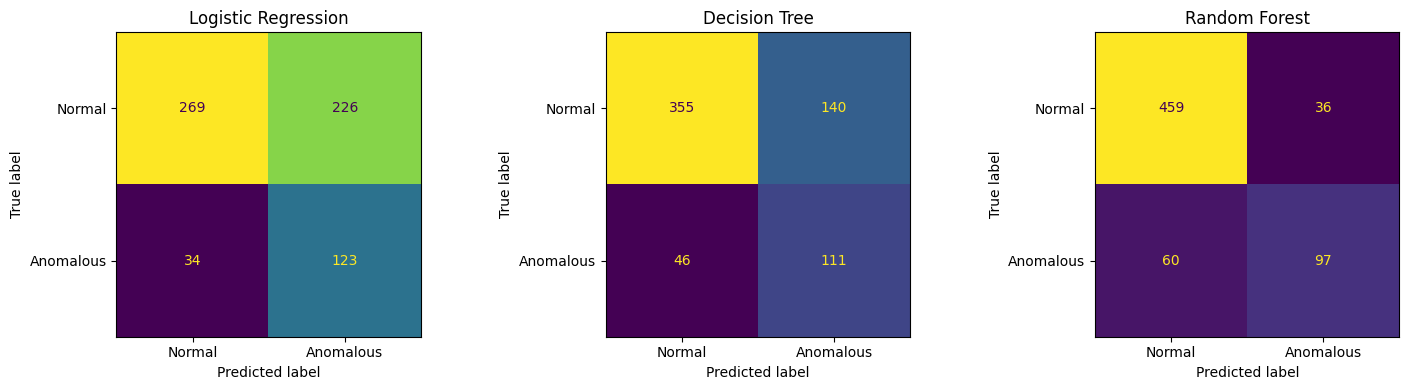

In [ ]:
fig, axes = plt.subplots(1, len(models), figsize=(5 * len(models), 4))
for ax, (name, preds) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, preds)
    ConfusionMatrixDisplay(cm, display_labels=['Normal', 'Anomalous']).plot(ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()


This cell visualizes the confusion matrix for each trained model. Confusion matrices provide a detailed breakdown of correct and incorrect classifications for both 'Normal' and 'Anomalous' classes, helping to understand the types of errors each model makes.

In [ ]:
for name, preds in predictions.items():
    print(f"--- {name} ---")
    print(classification_report(y_test, preds, target_names=['Normal', 'Anomalous']))


--- Logistic Regression ---
              precision    recall  f1-score   support

      Normal       0.89      0.54      0.67       495
   Anomalous       0.35      0.78      0.49       157

    accuracy                           0.60       652
   macro avg       0.62      0.66      0.58       652
weighted avg       0.76      0.60      0.63       652

--- Decision Tree ---
              precision    recall  f1-score   support

      Normal       0.89      0.72      0.79       495
   Anomalous       0.44      0.71      0.54       157

    accuracy                           0.71       652
   macro avg       0.66      0.71      0.67       652
weighted avg       0.78      0.71      0.73       652

--- Random Forest ---
              precision    recall  f1-score   support

      Normal       0.88      0.93      0.91       495
   Anomalous       0.73      0.62      0.67       157

    accuracy                           0.85       652
   macro avg       0.81      0.77      0.79       652
we

This cell prints a comprehensive classification report for each model. The report includes precision, recall, f1-score, and support for both the 'Normal' and 'Anomalous' classes, along with overall accuracy and macro/weighted averages.

In [ ]:
best_model_name = comparison_df.iloc[0]['Model']
best_model = models[best_model_name]
print(f"Best model selected: {best_model_name}")
comparison_df


Best model selected: Random Forest


,Model,Accuracy,Precision (anomaly),Recall (anomaly),F1 (anomaly)
0,Random Forest,0.852761,0.729323,0.617834,0.668966
1,Decision Tree,0.714724,0.442231,0.707006,0.544118
2,Logistic Regression,0.601227,0.352436,0.783439,0.486166


This cell identifies the best-performing model among the three trained models. It selects the model with the highest F1-score for the anomalous class from the `comparison_df` and prints its name, along with the full comparison table.

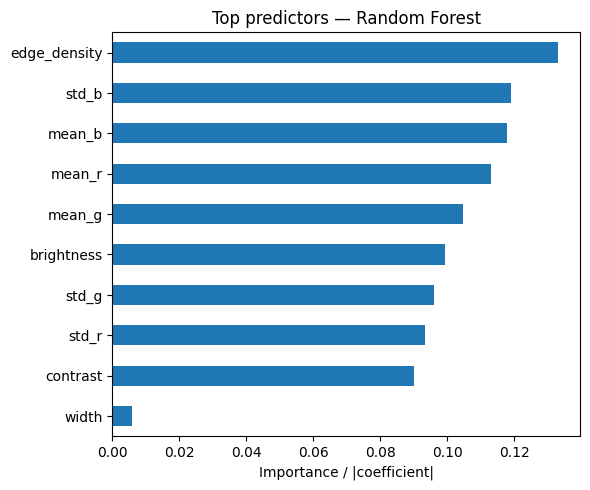

edge_density    0.132981
std_b           0.119105
mean_b          0.117950
mean_r          0.112923
mean_g          0.104675
brightness      0.099225
std_g           0.095979
std_r           0.093235
contrast        0.090172
width           0.005816
dtype: float64


In [ ]:
# Feature importance / coefficients for the selected model.
if best_model_name == 'Random Forest' or best_model_name == 'Decision Tree':
    importances = pd.Series(best_model.feature_importances_, index=X_train.columns)
    top_features = importances.sort_values(ascending=False).head(10)
elif best_model_name == 'Logistic Regression':
    coefs = pd.Series(best_model.coef_[0], index=X_train.columns)
    top_features = coefs.abs().sort_values(ascending=False).head(10)

top_features.plot(kind='barh', figsize=(6, 5), title=f'Top predictors — {best_model_name}')
plt.gca().invert_yaxis()
plt.xlabel('Importance / |coefficient|')
plt.tight_layout()
plt.show()

print(top_features)


This cell extracts and visualizes the top predictors for the best-selected model. For tree-based models (like Random Forest), it shows feature importances, while for Logistic Regression, it shows the absolute values of coefficients. This helps in understanding which features are most influential in the model's predictions.

In [ ]:
import pickle

MODEL_OUT_PATH = f"best_model_{best_model_name.replace(' ', '_').lower()}.joblib"
joblib.dump(best_model, MODEL_OUT_PATH)
joblib.dump(scaler, "feature_scaler.joblib")   # needed at inference time if the best model is Logistic Regression
joblib.dump(list(X.columns), "feature_columns.joblib")

print(f"Saved: {MODEL_OUT_PATH}")

DRIVE_SAVE_DIR = "/content/drive/MyDrive/mvtec_project_models"
os.makedirs(DRIVE_SAVE_DIR, exist_ok=True)
import shutil
for f in [MODEL_OUT_PATH, "feature_scaler.joblib", "feature_columns.joblib"]:
    shutil.copy(f, os.path.join(DRIVE_SAVE_DIR, f))
print(f"Also copied to Drive: {DRIVE_SAVE_DIR}")


Saved: best_model_random_forest.joblib
Also copied to Drive: /content/drive/MyDrive/mvtec_project_models


This cell saves the best-performing model, the feature scaler, and the list of feature column names to `.joblib` files. These files are then copied to a specified directory in Google Drive to ensure they are persistently stored and accessible for future use.

# Section 4 — Weeks 6–7 Streamlit Application Handoff

## Application status

The Streamlit prototype was developed from the selected model in Assignment 4. It is submitted separately because the application must run as a web application rather than as a Colab cell sequence.

The application contains these required sections:

- **Home:** project problem, objective and solution overview.
- **Data Dashboard:** dataset metrics, summary tables and three EDA charts.
- **Model Performance:** Logistic Regression, Decision Tree and Random Forest comparison, selected model and feature importance.
- **Make Prediction:** product-category selection, image upload, feature extraction and Normal/Defective prediction with probabilities.
- **About:** intended use, limitations and responsible-use statement.

## Model-to-application connection

The application loads `best_model_random_forest.joblib` without retraining. For each uploaded image, it reproduces the Assignment 4 feature-extraction process:

- image width and height;
- RGB channel means and standard deviations;
- brightness;
- contrast;
- Canny edge density;
- one-hot encoded product category.

The resulting 21-column input is arranged using `feature_columns.joblib` before prediction. The selected Random Forest achieved approximately **0.853 accuracy**, **0.729 anomaly precision**, **0.618 anomaly recall** and **0.669 anomaly F1-score** on the held-out test set.

## Streamlit submission files

- `app.py`
- `best_model_random_forest.joblib`
- `feature_columns.joblib`
- `cleaned_project_dataset.csv`
- `week5_6_model_comparison.csv`
- `requirements.txt`
- `README.md`
- `WEEK6_7_TECHNICAL_REPORT.md`

## Running the application

```bash
pip install -r requirements.txt
streamlit run app.py
```

## Limitation

This prototype is an educational engineered-feature baseline. It does not perform the final PatchCore workflow with deep embeddings, patch-level distances or a normal-only memory bank. Production use would require further image-based validation and domain-expert review.
